In [1]:
from deepanc.common.utils import loading_paths_from_MAT, nmse
from deepanc.common.Disturbance_generation import Disturbance_generation_from_real_noise
from deepanc.inference.loading_real_wave_noise import loading_real_wave_noise
from deepanc.inference.antinoise_generator import Deep_ANC_controller
import numpy as np
import torch

In [2]:
from pyprojroot import here
PROJECT_ROOT = here()
MODEL_DIR = PROJECT_ROOT / "models"
PATHS_DIR = PROJECT_ROOT / "rirs"
NOISE_DIR = PROJECT_ROOT / "Dataset" / "test"
FIG_DIR = PROJECT_ROOT / "figs"
print(PROJECT_ROOT)
print(MODEL_DIR)
print(PATHS_DIR)
print(NOISE_DIR)


/home/rkobayashi/anc/deepanc
/home/rkobayashi/anc/deepanc/models
/home/rkobayashi/anc/deepanc/rirs
/home/rkobayashi/anc/deepanc/Dataset/test


In [3]:
fs = 16000
Pri_path, Sec_path = loading_paths_from_MAT(PATHS_DIR, "rt60_0.2s", "Primary_path.mat", "Secondary_path.mat", )
sound_names = [ sound_name for sound_name in NOISE_DIR.iterdir() ]
sound_name = sound_names[0].name
waveform, resample_rate = loading_real_wave_noise(NOISE_DIR, sound_name)
Dis, _, Re = Disturbance_generation_from_real_noise(fs, 0, waveform, Pri_path, Sec_path)
Time = np.arange(len(Dis)) / fs
Sec_path = torch.tensor(Sec_path)

In [5]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
delay = 1
eta = torch.tensor([1])
controller = Deep_ANC_controller(MODEL_DIR/"delay_1.pth", device, fs, delay, eta, Sec_path)
Error = controller.noise_cancellation(Dis, Re)[0]
Dis = Dis.tolist()

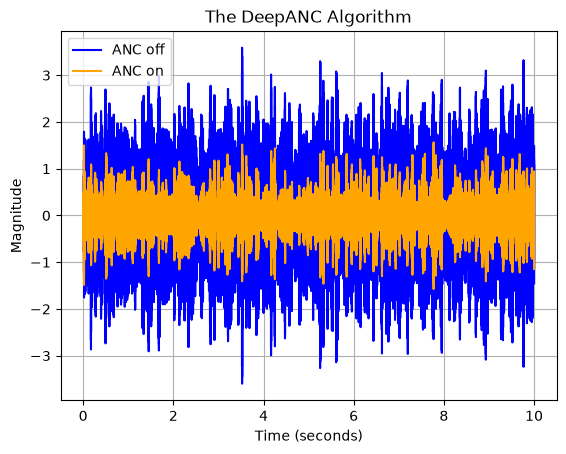

In [6]:
import matplotlib.pyplot as plt
plt.title('The DeepANC Algorithm')
plt.plot(Time, Dis, color='blue', label='ANC off')
plt.plot(Time, Error, color='orange', label='ANC on')
plt.ylabel('Magnitude')
plt.xlabel('Time (seconds)')
plt.legend()
plt.grid()
plt.savefig(FIG_DIR/'DeepANC.png', dpi=600, bbox_inches='tight', pad_inches=0)
plt.show()

In [7]:
Error = torch.tensor(Error)
Dis = torch.tensor(Dis)
nmse(Error, Dis)

tensor(-9.9999)